<a href="https://colab.research.google.com/github/group6aiml-hub/NIDS_AInML/blob/main/07_model_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Loading the project files from GitHub, preparing the datasets using Jesper's data pipeline, and displaying the number of training and validation samples, features, and target classes.

In [ ]:
!pip install -q imbalanced-learn nbformat

import os
import sys

repo_path = '/content/NIDS_AInML'

if not os.path.exists(repo_path):
    !git clone -q https://github.com/group6aiml-hub/NIDS_AInML.git
else:
    !git -C /content/NIDS_AInML pull --ff-only

sys.path.insert(0, f'{repo_path}/src')

from data import last_data

d_valentino = last_data(path=f'{repo_path}/datasets/')
d_shared = last_data(path=f'{repo_path}/datasets/')

import numpy as np

assert d_valentino["X_tr"].index.equals(d_shared["X_tr"].index)
assert d_valentino["X_val"].index.equals(d_shared["X_val"].index)

assert np.array_equal(
    d_valentino["y_val_mc"],
    d_shared["y_val_mc"]
)

assert np.array_equal(
    d_valentino["y_val_bin"],
    d_shared["y_val_bin"]
)

print("Training and validation datasets match!")

print("---Dataset used for Gradient Boosting---")
print("Training:", d_valentino['X_tr'].shape)
print("Validation:", d_valentino['X_val'].shape)
print("Classes:", d_valentino['le'].classes_)

print("\n---Dataset used for Neural Network and Error Analysis---")
print("Training:", d_shared['X_tr'].shape)
print("Validation:", d_shared['X_val'].shape)
print("Classes:", d_shared['le'].classes_)




Training and validation datasets match!
---Dataset used for Gradient Boosting---
Training: (86192, 41)
Validation: (21548, 41)
Classes: ['Analysis' 'Backdoor' 'DoS' 'Exploits' 'Fuzzers' 'Generic' 'Normal'
 'Reconnaissance' 'Shellcode' 'Worms']

---Dataset used for Neural Network and Error Analysis---
Training: (86192, 41)
Validation: (21548, 41)
Classes: ['Analysis' 'Backdoor' 'DoS' 'Exploits' 'Fuzzers' 'Generic' 'Normal'
 'Reconnaissance' 'Shellcode' 'Worms']


In [ ]:
import nbformat

d = d_valentino

valentino_notebook = nbformat.read(
    f'{repo_path}/notebooks/07_gradiant_boosting.ipynb',
    as_version=4
)

print("Valentino's Notebook has been loaded.")
print("Number of cells:", len(valentino_notebook.cells))


Valentino's Notebook has been loaded.
Number of cells: 8


In [ ]:
import io
from contextlib import redirect_stdout

output = io.StringIO()

try:
    with redirect_stdout(output):
        exec(valentino_notebook.cells[2].source)

        exec(valentino_notebook.cells[3].source)
        predictions_valentino_binary = y_pred.copy()

        exec(valentino_notebook.cells[5].source)

except Exception:
    print(output.getvalue())
    raise

else:
    print("The Gradient Boosting model is ready!\n")
    print(output.getvalue())


The Gradient Boosting model is ready!

Conversion complete! Now the data is ready.
--- BINARY TASK RESULTS ---
Training time: 2.76 seconds
Macro-F1 (Validation): 0.9130

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.91      0.91     10378
           1       0.92      0.92      0.92     11170

    accuracy                           0.91     21548
   macro avg       0.91      0.91      0.91     21548
weighted avg       0.91      0.91      0.91     21548

Original training set size (multi-class): (86192, 56)
Training set size AFTER SMOTE: (415120, 56)

Starting Gradient Boosting Training with SMOTE...

--- GRADIENT BOOSTING RESULTS WITH SMOTE (MULTI-CLASS) ---
Training time: 113.34 seconds
Macro-F1 (Validation): 0.5751

Classification Report:
              precision    recall  f1-score   support

           0       0.16      0.52      0.24       319
           1       0.18      0.44      0.26       307
           2       0.41 

In [ ]:
import nbformat

hubert_notebook = nbformat.read(
    f'{repo_path}/notebooks/07_neural_network.ipynb',
    as_version=4
)

print("Hubert's notebook loaded successfully.")
print("Number of cells:", len(hubert_notebook.cells))

Hubert's notebook loaded successfully.
Number of cells: 17


In [ ]:
import io
import pandas as pd
from contextlib import redirect_stdout
from sklearn.neural_network import MLPClassifier

d = d_shared

hubert_code = hubert_notebook.cells[15].source

trained_hubert_models = {}
trained_hubert_binary_models = {}

assert "resultater.append(rad)" in hubert_code, (
    "Hubert's notebook has changed. Check model extraction."
)

assert "    # Multiklasse (med SMOTE)" in hubert_code, (
    "Hubert's notebook has changed. Check binary model extraction."
)

hubert_code = hubert_code.replace(
    "    # Multiklasse (med SMOTE)",
    "    trained_hubert_binary_models[navn] = p\n\n"
    "    # Multiklasse (med SMOTE)"
)

hubert_code = hubert_code.replace(
    "resultater.append(rad)",
    "trained_hubert_models[navn] = p\n    resultater.append(rad)"
)

hubert_namespace = {
    "d": d_shared,
    "trained_hubert_models": trained_hubert_models,
    "trained_hubert_binary_models": trained_hubert_binary_models
}

output = io.StringIO()

try:
    with redirect_stdout(output):

        exec(hubert_code, hubert_namespace)

        test_modell = hubert_namespace["test_modell"]
        resultater = hubert_namespace["resultater"]

        test_modell(
            "NN 3: Tanh Function",
            lambda: MLPClassifier(
                activation="tanh",
                max_iter=200,
                solver="sgd",
                learning_rate_init=0.05337,
                random_state=42
            )
        )

        test_modell(
            "NN 4: Identity Function",
            lambda: MLPClassifier(
                activation="identity",
                max_iter=200,
                solver="sgd",
                learning_rate_init=0.05337,
                random_state=42
            )
        )

except Exception:
    print(output.getvalue())
    raise

else:
    print("Hubert's Neural Network models are ready!\n")
    print(output.getvalue())

expected_models = [
    "NN 1: RELU Function",
    "NN 2: Logistic Sigmoid Function",
    "NN 3: Tanh Function",
    "NN 4: Identity Function"
]

for name in expected_models:
    assert name in trained_hubert_models, (
        f"Missing trained model: {name}"
    )

print("\nModels available for evaluation:")
for name in trained_hubert_models:
    print("-", name)

display(pd.DataFrame(resultater).set_index("Modell").round(3))

for name in expected_models:
    assert name in trained_hubert_binary_models, (
        f"Missing binary model: {name}"
    )

print("\nBinary models available for evaluation:")
for name in trained_hubert_binary_models:
    print("-", name)


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


Hubert's Neural Network models are ready!

===== NN 1: RELU Function (multiklasse)
                precision    recall  f1-score   support

      Analysis      0.174     0.351     0.233       319
      Backdoor      0.192     0.567     0.286       307
           DoS      0.361     0.252     0.297       761
      Exploits      0.804     0.798     0.801      3969
       Fuzzers      0.718     0.683     0.700      3230
       Generic      0.983     0.816     0.892       836
        Normal      0.939     0.903     0.921     10378
Reconnaissance      0.863     0.699     0.773      1504
     Shellcode      0.428     0.775     0.551       218
         Worms      0.085     0.538     0.147        26

      accuracy                          0.796     21548
     macro avg      0.555     0.638     0.560     21548
  weighted avg      0.829     0.796     0.808     21548

===== NN 2: Logistic Sigmoid Function (multiklasse)
                precision    recall  f1-score   support

      Analysis      0

,Tid binær (s),Binær macro-F1,Recall angrep,Tid multi (s),Multi macro-F1
Modell,,,,,
NN 1: RELU Function,101.6,0.924,0.939,145.8,0.560
NN 2: Logistic Sigmoid Function,131.2,0.925,0.942,165.5,0.558
NN 3: Tanh Function,103.8,0.924,0.935,165.0,0.554
NN 4: Identity Function,24.9,0.909,0.964,44.3,0.468



Binary models available for evaluation:
- NN 1: RELU Function
- NN 2: Logistic Sigmoid Function
- NN 3: Tanh Function
- NN 4: Identity Function


In [ ]:
d_shared = last_data(path=f'{repo_path}/datasets/')

predictions = {
    "Gradient Boosting": y_pred_gb_smote.copy(),
    "Neural Network - ReLU": trained_hubert_models[
        "NN 1: RELU Function"
    ].predict(d_shared["X_val"]),
    "Neural Network - Sigmoid": trained_hubert_models[
        "NN 2: Logistic Sigmoid Function"
    ].predict(d_shared["X_val"]),
    "Neural Network - Tanh": trained_hubert_models[
        "NN 3: Tanh Function"
    ].predict(d_shared["X_val"]),
    "Neural Network - Identity": trained_hubert_models[
        "NN 4: Identity Function"
    ].predict(d_shared["X_val"])
}

y_true = d_shared["y_val_mc"]

assert (
    d_valentino["y_val_mc"] == d_shared["y_val_mc"]).all(), "Validation labels do not match!"

for name, y_pred in predictions.items():
    assert len(y_pred) == len(y_true), f"Incorrect prediction length: {name}"
    print(f"{name}: {len(y_pred)} predictions")

print("Actual labels:", len(y_true))


Gradient Boosting: 21548 predictions
Neural Network - ReLU: 21548 predictions
Neural Network - Sigmoid: 21548 predictions
Neural Network - Tanh: 21548 predictions
Neural Network - Identity: 21548 predictions
Actual labels: 21548


In [ ]:
import nbformat

oliver_notebook = nbformat.read(
    f'{repo_path}/notebooks/07_random_forest.ipynb',
    as_version=4
)

print("Oliver's notebook loaded successfully.")
print("Number of cells:", len(oliver_notebook.cells))

Oliver's notebook loaded successfully.
Number of cells: 14


In [ ]:
import pandas as pd
import time
import numpy as np
from sklearn.metrics import f1_score, classification_report
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

X_train = d_shared["X_tr"].sample(
    n=30000,
    random_state=42
)

y_train = pd.Series(
    d_shared["y_tr_bin"],
    index=d_shared["X_tr"].index
).loc[X_train.index]

X_val = d_shared["X_val"]
y_val = d_shared["y_val_bin"]

num_cols = X_train.select_dtypes(
    include="number"
).columns.tolist()

cat_cols = X_train.select_dtypes(
    exclude="number"
).columns.tolist()

oliver_namespace = {
    "X_train": X_train,
    "X_test": X_val,
    "num_cols": num_cols,
    "cat_cols": cat_cols,
    "np": np,
    "Pipeline": Pipeline,
    "ColumnTransformer": ColumnTransformer,
    "OneHotEncoder": OneHotEncoder,
    "SimpleImputer": SimpleImputer,
    "RandomForestClassifier": RandomForestClassifier
}

exec(oliver_notebook.cells[4].source, oliver_namespace)

oliver_model = oliver_namespace["model"]

start_time = time.time()
oliver_model.fit(X_train, y_train)
oliver_train_time = time.time() - start_time

predictions_oliver = oliver_model.predict(X_val)

print("Oliver's Random Forest is ready!")
print("Training time:", round(oliver_train_time, 2), "seconds")
print("Macro-F1:", round(
    f1_score(y_val, predictions_oliver, average="macro"), 3
))
print(classification_report(
    y_val,
    predictions_oliver,
    target_names=["Normal", "Attack"],
    zero_division=0
))

Model created successfully.
Oliver's Random Forest is ready!
Training time: 9.33 seconds
Macro-F1: 0.929
              precision    recall  f1-score   support

      Normal       0.95      0.90      0.92     10378
      Attack       0.91      0.96      0.93     11170

    accuracy                           0.93     21548
   macro avg       0.93      0.93      0.93     21548
weighted avg       0.93      0.93      0.93     21548



In [ ]:
import numpy as np

binary_predictions = {
    "Random Forest": predictions_oliver,

    "Decision Tree": predictions_valentino_binary,

    "Neural Network - ReLU": trained_hubert_binary_models[
        "NN 1: RELU Function"
    ].predict(d_shared["X_val"]),

    "Neural Network - Sigmoid": trained_hubert_binary_models[
        "NN 2: Logistic Sigmoid Function"
    ].predict(d_shared["X_val"]),

    "Neural Network - Tanh": trained_hubert_binary_models[
        "NN 3: Tanh Function"
    ].predict(d_shared["X_val"]),

    "Neural Network - Identity": trained_hubert_binary_models[
        "NN 4: Identity Function"
    ].predict(d_shared["X_val"])
}

y_true_binary = d_shared["y_val_bin"]

assert np.array_equal(
    d_valentino["y_val_bin"],
    d_shared["y_val_bin"]
), "Binary validation labels do not match!"

for name, y_pred in binary_predictions.items():
    assert len(y_pred) == len(y_true_binary), (
        f"Incorrect number of predictions: {name}"
    )

    print(f"{name}: {len(y_pred)} predictions")

print("Actual labels:", len(y_true_binary))

Random Forest: 21548 predictions
Decision Tree: 21548 predictions
Neural Network - ReLU: 21548 predictions
Neural Network - Sigmoid: 21548 predictions
Neural Network - Tanh: 21548 predictions
Neural Network - Identity: 21548 predictions
Actual labels: 21548


In [ ]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

binary_results = []

for name, y_pred in binary_predictions.items():
    binary_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_true_binary, y_pred),
        "Precision": precision_score(
            y_true_binary, y_pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_true_binary, y_pred, average="macro", zero_division=0
        ),
        "Macro-F1": f1_score(
            y_true_binary, y_pred, average="macro", zero_division=0
        ),
        "Attack Recall": recall_score(
            y_true_binary, y_pred, pos_label=1, zero_division=0
        )
    })

binary_results_df = pd.DataFrame(binary_results)

display(
    binary_results_df.sort_values(
        by="Macro-F1",
        ascending=False
    ).round(3)
)


,Model,Accuracy,Precision,Recall,Macro-F1,Attack Recall
0,Random Forest,0.929,0.931,0.928,0.929,0.959
3,Neural Network - Sigmoid,0.925,0.926,0.925,0.925,0.942
2,Neural Network - ReLU,0.924,0.925,0.923,0.924,0.939
4,Neural Network - Tanh,0.924,0.924,0.923,0.924,0.935
1,Decision Tree,0.913,0.913,0.913,0.913,0.918
5,Neural Network - Identity,0.910,0.915,0.907,0.909,0.964


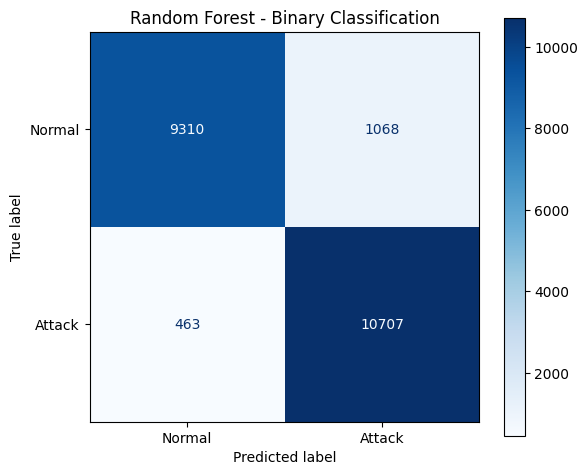

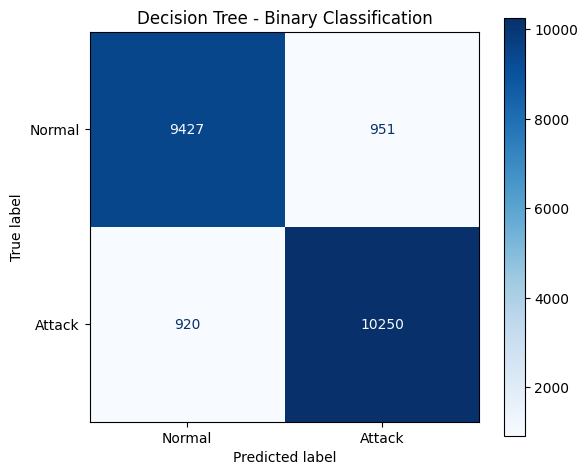

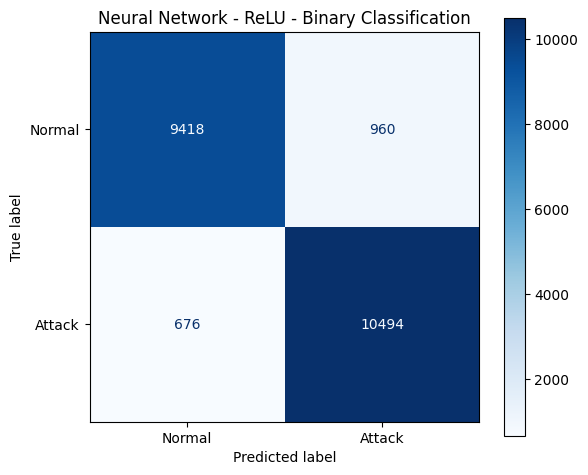

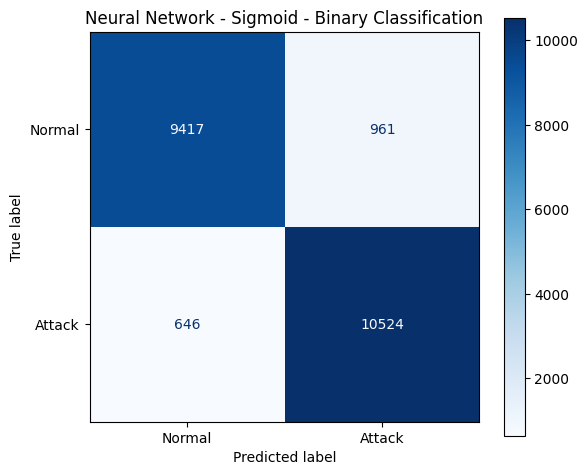

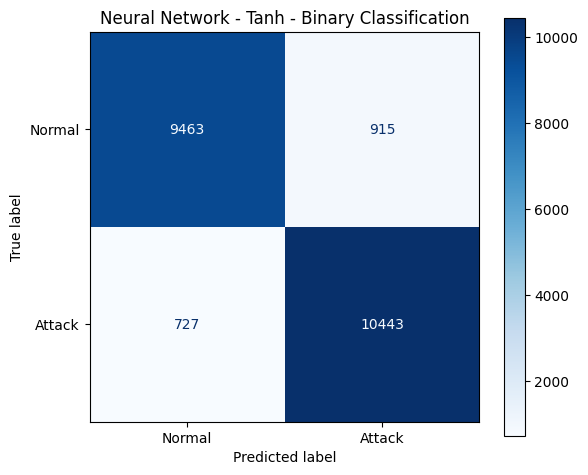

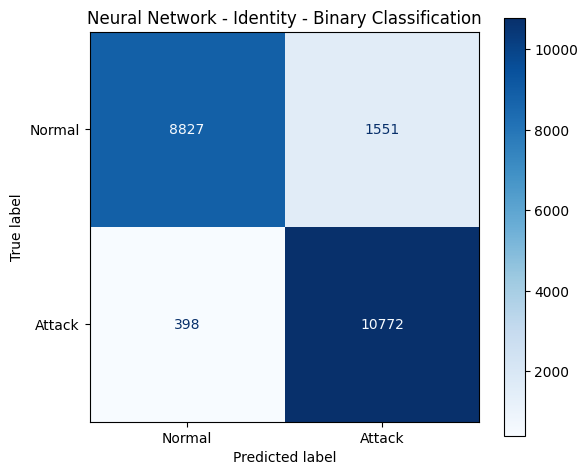

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

for name, y_pred in binary_predictions.items():
    fig, ax = plt.subplots(figsize=(6, 5))

    ConfusionMatrixDisplay.from_predictions(
        y_true_binary,
        y_pred,
        labels=[0, 1],
        display_labels=["Normal", "Attack"],
        cmap="Blues",
        values_format="d",
        ax=ax
    )

    ax.set_title(f"{name} - Binary Classification")

    plt.tight_layout()

    filename = name.lower().replace(" - ", "_").replace(" ", "_")
    plt.savefig(
        f"{filename}_binary_cm.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

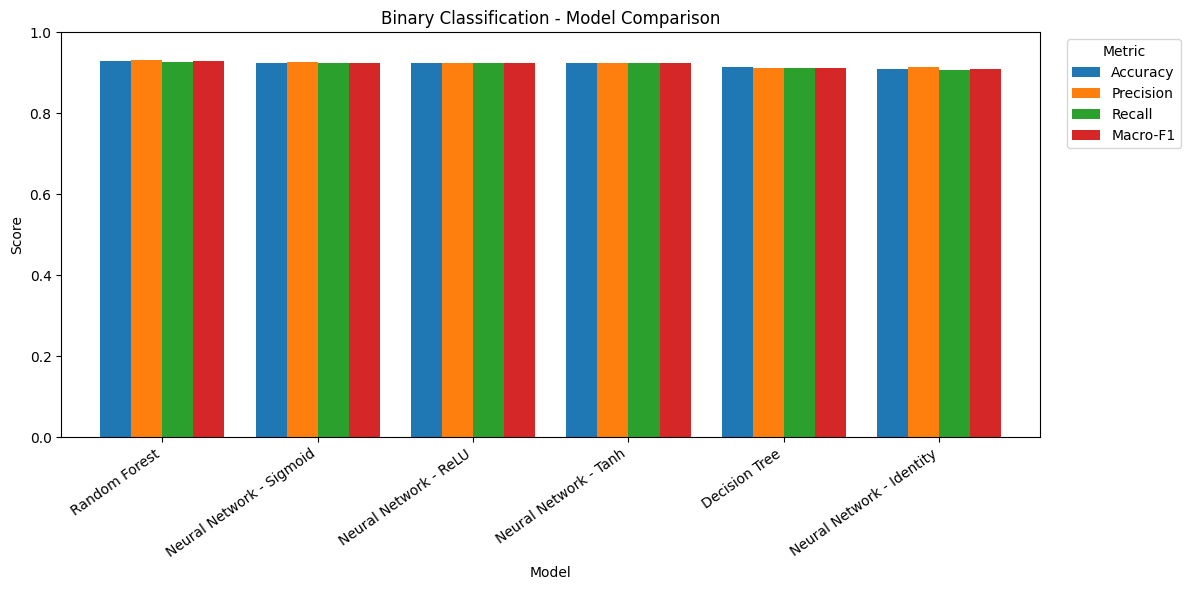

In [ ]:
import matplotlib.pyplot as plt

metrics = ["Accuracy", "Precision", "Recall", "Macro-F1"]

plot_data = binary_results_df.sort_values(
    by="Macro-F1",
    ascending=False
).set_index("Model")

ax = plot_data[metrics].plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

ax.set_title("Binary Classification - Model Comparison")
ax.set_xlabel("Model")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.legend(title="Metric", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.xticks(rotation=35, ha="right")
plt.tight_layout()

plt.savefig(
    "binary_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

def evaluate_model(name, y_true, y_pred):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro-F1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        )
    }

results = pd.DataFrame([
    evaluate_model(name, y_true, y_pred)
    for name, y_pred in predictions.items()
])

display(results.round(3))


,Model,Accuracy,Precision,Recall,Macro-F1
0,Gradient Boosting,0.790,0.558,0.693,0.575
1,Neural Network - ReLU,0.796,0.555,0.638,0.560
2,Neural Network - Sigmoid,0.798,0.561,0.645,0.558
3,Neural Network - Tanh,0.799,0.555,0.621,0.554
4,Neural Network - Identity,0.733,0.477,0.585,0.468


In [ ]:
from sklearn.metrics import classification_report

class_names = d_shared["le"].classes_
class_ids = list(range(len(class_names)))

def get_class_results(y_pred):
    report = classification_report(
        y_true,
        y_pred,
        labels=class_ids,
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    return pd.DataFrame(report).T.loc[
        class_names, ["precision", "recall", "f1-score", "support"]
    ]

comparison_classes = pd.DataFrame({
    name: get_class_results(y_pred)["f1-score"]
    for name, y_pred in predictions.items()
})

display(comparison_classes.round(3))



,Gradient Boosting,Neural Network - ReLU,Neural Network - Sigmoid,Neural Network - Tanh,Neural Network - Identity
Analysis,0.242,0.233,0.190,0.178,0.244
Backdoor,0.256,0.286,0.299,0.283,0.240
DoS,0.326,0.297,0.309,0.258,0.071
Exploits,0.792,0.801,0.809,0.810,0.727
Fuzzers,0.727,0.700,0.701,0.699,0.633
Generic,0.887,0.892,0.893,0.892,0.866
Normal,0.912,0.921,0.921,0.921,0.902
Reconnaissance,0.803,0.773,0.766,0.773,0.552
Shellcode,0.572,0.551,0.564,0.570,0.392
Worms,0.235,0.147,0.130,0.153,0.053


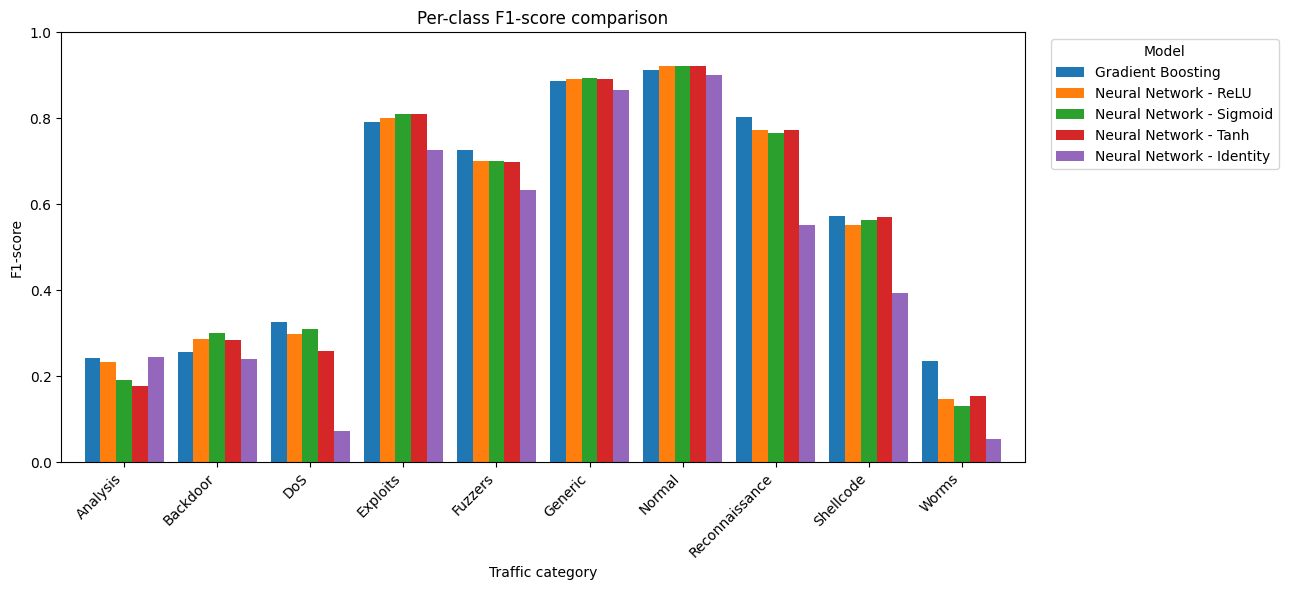

In [ ]:
import matplotlib.pyplot as plt

ax = comparison_classes.plot(
    kind="bar",
    figsize=(13, 6),
    width=0.85
)

ax.set_ylabel("F1-score")
ax.set_xlabel("Traffic category")
ax.set_title("Per-class F1-score comparison")
ax.set_ylim(0, 1)
ax.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("model_class_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


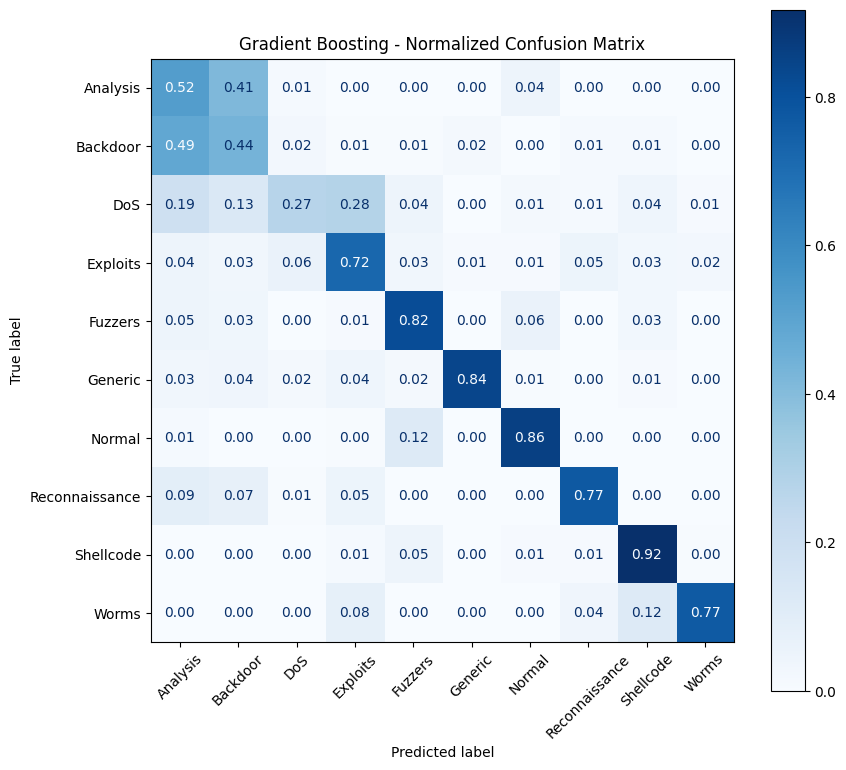

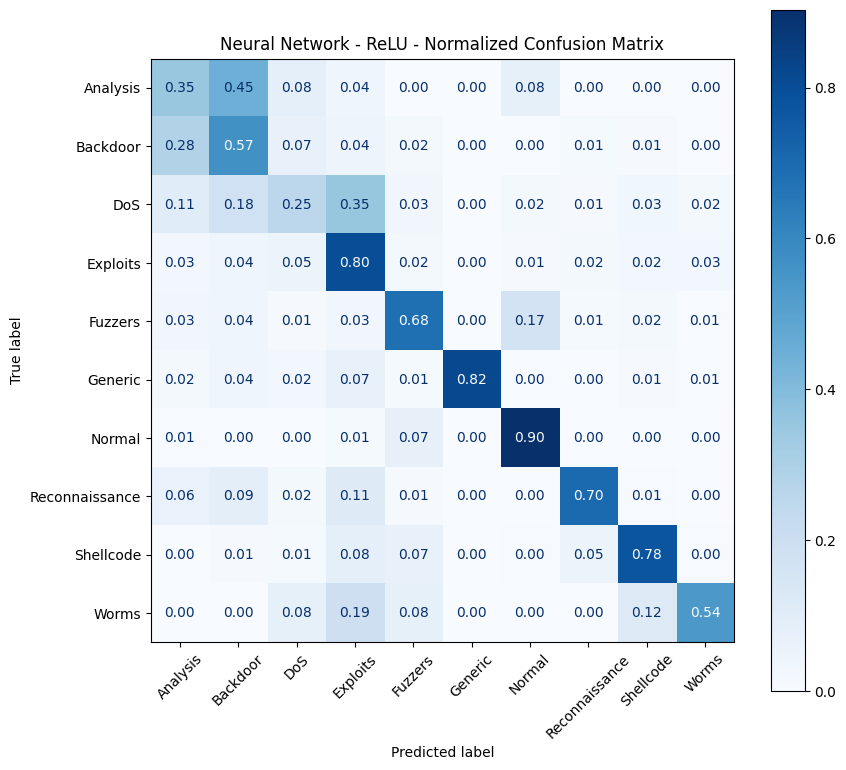

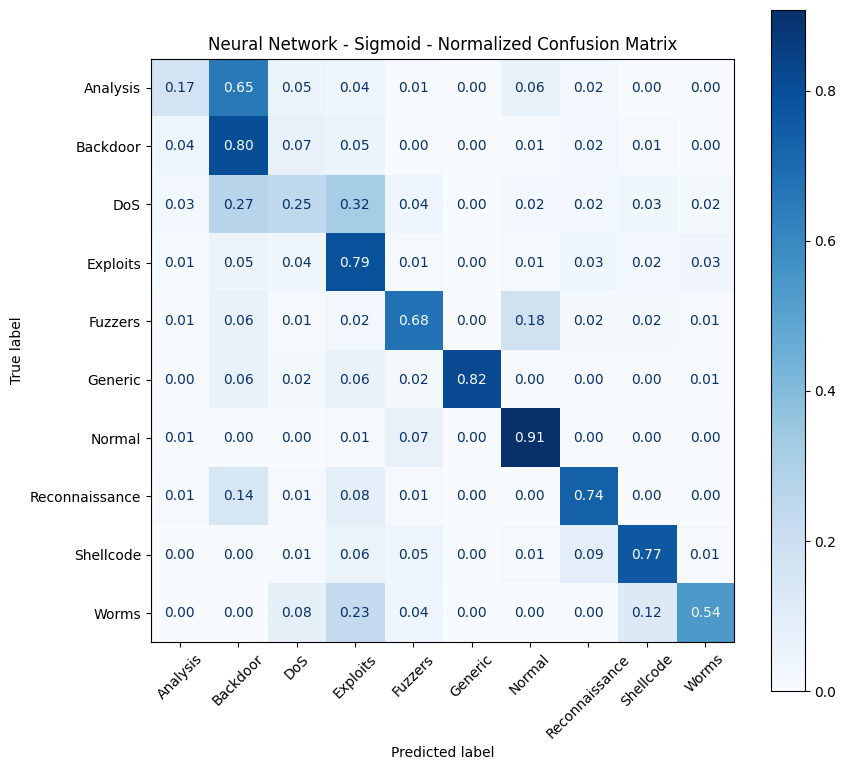

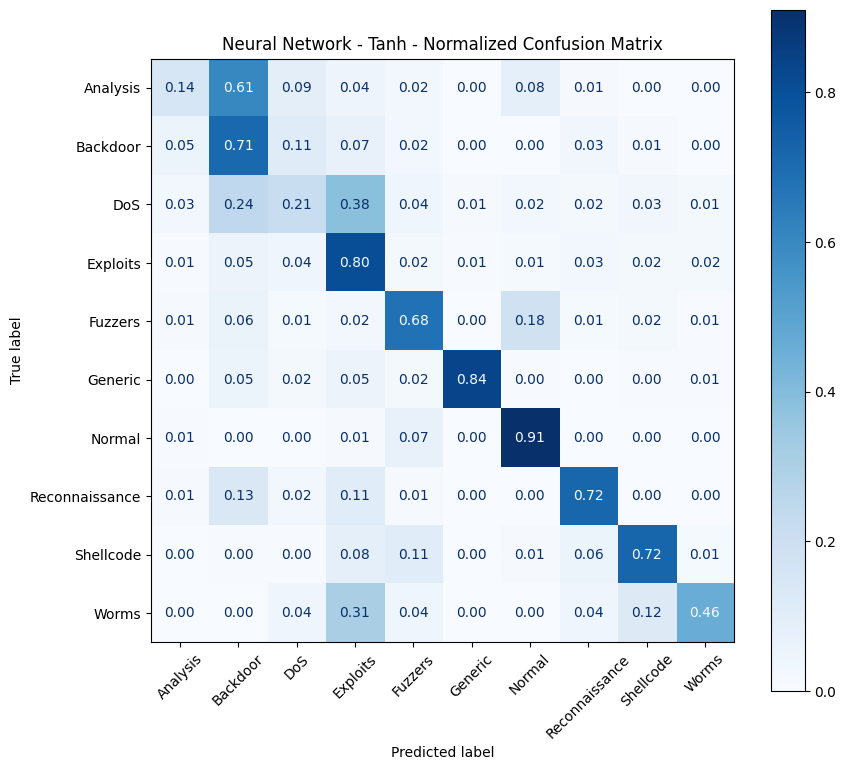

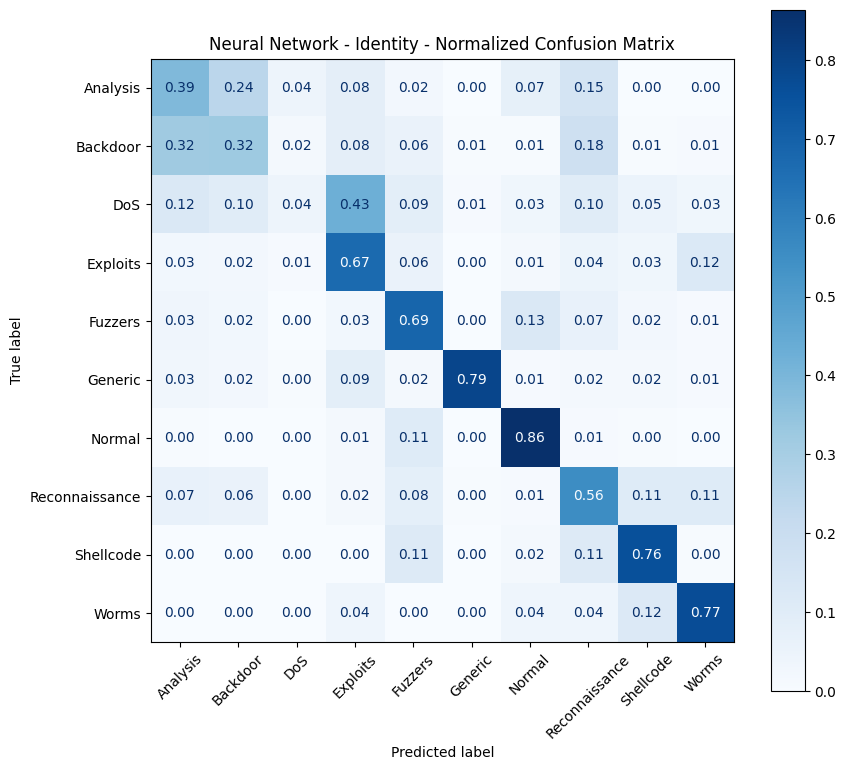

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

for name, y_pred in predictions.items():
    fig, ax = plt.subplots(figsize=(9, 8))

    ConfusionMatrixDisplay.from_predictions(
        y_true,
        y_pred,
        labels=class_ids,
        display_labels=class_names,
        normalize="true",
        cmap="Blues",
        values_format=".2f",
        xticks_rotation=45,
        ax=ax
    )

    ax.set_title(f"{name} - Normalized Confusion Matrix")

    plt.tight_layout()

    filename = name.lower().replace(" - ", "_").replace(" ", "_")
    plt.savefig(f"{filename}_cm.png", dpi=300, bbox_inches="tight")
    plt.show()

